# Exploring the airline tweets

What's in the data, what's wrong with it, and what the model gets wrong. The production code lives in `src/`; this notebook is where the decisions in it came from.

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.data import load_raw, prepare, repair_label_leak
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False, "axes.spines.right": False})
raw = load_raw()
print(raw.shape)
raw[["airline", "airline_sentiment", "negativereason", "text"]].head()

(14640, 15)


,airline,airline_sentiment,negativereason,text
0,Virgin America,neutral,NaN,@VirginAmerica What @dhepburn said.
1,Virgin America,positive,NaN,@VirginAmerica plus you've added commercials t...
2,Virgin America,neutral,NaN,@VirginAmerica I didn't today... Must mean I n...
3,Virgin America,negative,Bad Flight,@VirginAmerica it's really aggressive to blast...
4,Virgin America,negative,Can't Tell,@VirginAmerica and it's a really big bad thing...


## 1. A find-and-replace left the labels inside the text

Reading samples turned up words like "Cancelled Flightled" and "Late Flightr". Someone replaced "cancel" and "late" with the label names before the data was released.

In [2]:
for pat in ["Cancelled Flight", "Late Flight"]:
    hit = raw["text"].str.contains(pat, regex=False)
    print(f"{pat!r} appears in {hit.sum():,} tweets ({hit.mean():.1%})")
raw.loc[raw["text"].str.contains("Cancelled Flightled", regex=False), "text"].head(3).tolist()

'Cancelled Flight' appears in 1,020 tweets (7.0%)
'Late Flight' appears in 451 tweets (3.1%)


['@VirginAmerica I like the TV and interesting video . Just disappointed in Cancelled Flightled flight when other flights went out to jfk on Saturday .',
 '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?',
 '@VirginAmerica @ChrysiChrysic your assistance yesterday when u Cancelled Flightled our flight was to give us a hotel hotline  Shame on you!']

In [3]:
# The replacement was mechanical, so it reverses exactly.
[repair_label_leak(t) for t in raw.loc[raw["text"].str.contains("Flightled|Flightr", regex=True), "text"].head(3)]

['@VirginAmerica I like the TV and interesting video . Just disappointed in cancelled flight when other flights went out to jfk on Saturday .',
 '@VirginAmerica is flight 882 cancelled and what do I do if it is?',
 '@VirginAmerica @ChrysiChrysic your assistance yesterday when u cancelled our flight was to give us a hotel hotline  Shame on you!']

## 2. Duplicates and the time split

In [4]:
df = prepare(raw)
print(f"{len(raw) - len(df)} duplicate tweets removed (mostly retweets), {len(df):,} left")
df.groupby("split")["created"].agg(["min", "max", "count"])

336 duplicate tweets removed (mostly retweets), 14,304 left


,min,max,count
split,,,
test,2015-02-23 00:02:21,2015-02-24 11:53:37,4143
train,2015-02-16 23:36:05,2015-02-21 23:52:05,7108
val,2015-02-22 00:00:51,2015-02-22 23:58:41,3053


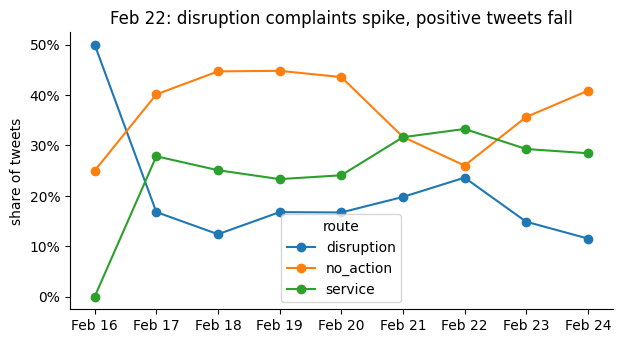

In [5]:
by_day = pd.crosstab(df["created"].dt.strftime("%b %d"), df["route"], normalize="index")
ax = by_day[["disruption", "no_action", "service"]].plot(marker="o")
ax.set(ylabel="share of tweets", xlabel="", title="Feb 22: disruption complaints spike, positive tweets fall")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"));

Feb 22 isn't like the days before it. That's why the split is by time: a random split would hide shifts like this, and a production model meets them on day one. It's also the day the drift monitor flags in `src/replay.py`.

## 3. What the champion gets wrong

In [6]:
import joblib, json
from sklearn.metrics import confusion_matrix, classification_report
from src.data import ROUTES
models = joblib.load("../models/v1/model.joblib")
test = df[df["split"] == "test"]
pred = models["route"].predict(test["clean"])
print(classification_report(test["route"], pred, labels=ROUTES, digits=3))

              precision    recall  f1-score   support

   no_action      0.777     0.750     0.763      1538
     baggage      0.729     0.691     0.709       272
  disruption      0.650     0.712     0.680       577
     booking      0.413     0.341     0.374       167
     service      0.670     0.715     0.692      1204
     general      0.328     0.294     0.310       385

    accuracy                          0.672      4143
   macro avg      0.594     0.584     0.588      4143
weighted avg      0.669     0.672     0.670      4143



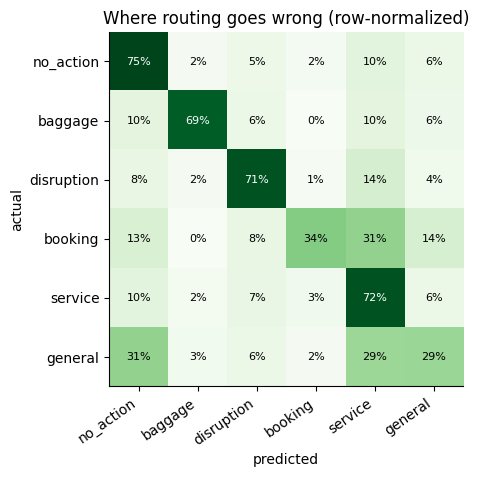

In [7]:
cm = pd.DataFrame(confusion_matrix(test["route"], pred, labels=ROUTES, normalize="true"), index=ROUTES, columns=ROUTES)
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.imshow(cm.values, cmap="Greens")
ax.set_xticks(range(6), ROUTES, rotation=35, ha="right"); ax.set_yticks(range(6), ROUTES)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm.values[i, j]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if cm.values[i, j] > 0.5 else "black")
ax.set(xlabel="predicted", ylabel="actual", title="Where routing goes wrong (row-normalized)");

The weakest queues are **booking** and **general**, and most of their errors go to **service** or **no_action**. Those boundaries are fuzzy even for people. Baggage and disruption, where the vocabulary is specific ("bag", "cancelled", "delayed"), route best.

In [8]:
conf = models["route"].predict_proba(test["clean"]).max(1)
agree = test["negativereason_confidence"].fillna(1.0)
print("labeler agreement where the model is right: %.2f, wrong: %.2f" % (agree[pred == test["route"]].mean(), agree[pred != test["route"]].mean()))

labeler agreement where the model is right: 0.79, wrong: 0.59


The model misses most on tweets the human labelers disagreed about too. Some of the "error" is label noise, which caps how good any model can look on this data.

## 4. Unsupervised: what's hiding in "Can't Tell"?

1,190 negative tweets were labeled "Can't Tell". If they contain coherent themes, the general queue could be split.

In [9]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
unclear = df[df["negativereason"] == "Can't Tell"]["clean"]
tfidf = TfidfVectorizer(stop_words="english", min_df=4, max_df=0.5, token_pattern=r"[a-z][a-z']+")
X = tfidf.fit_transform(unclear.str.lower().str.replace("@airline", "").str.replace("@user", ""))
nmf = NMF(n_components=6, random_state=0, init="nndsvda", max_iter=500).fit(X)
words = np.array(tfidf.get_feature_names_out())
topics = nmf.transform(X).argmax(1)
for k, comp in enumerate(nmf.components_):
    print(f"topic {k} ({(topics == k).mean():.0%}):", ", ".join(words[comp.argsort()[-8:][::-1]]))

topic 0 (11%): worst, airline, experience, far, time, travel, world, i've
topic 1 (8%): url, fleek, fleet's, rt, hate, stop, run, can't
topic 2 (47%): i'm, fly, flying, help, time, don't, united, need
topic 3 (18%): flight, pay, problems, plane, thanks, did, booking, hour
topic 4 (11%): just, lost, that's, day, business, care, heard, trip
topic 5 (5%): guys, suck, ass, thanks, experience, good, flights, know


In [10]:
for k in range(3):
    print(f"--- topic {k}")
    for t in unclear[topics == k].head(2): print("  ", t[:120])

--- topic 0
   @airline should i continue?
   @airline why are you the ONLY airline that is not flying out of BNA today?
--- topic 1
   @airline Bad coffee, but the juice is ok. #GetPhilz @ United Terminal SFO Airport <url>
   @airline 's first-class #cockup <url>
--- topic 2
   @airline is REALLY getting on my nerves !! 😡😡 #nothappy
   . @airline nothing apparently. I've flown w/ you 4 times in last 3 weeks and 3 of those experiences (incl today) were cl


Mostly, there isn't much hiding. Nearly half the "Can't Tell" tweets land in one diffuse topic of general frustration ("getting on my nerves", "need help"). Two smaller topics are coherent: complaints about the airline's reputation overall ("worst airline experience"), and a cluster of retweets of a meme ("fleets on fleek") that has nothing to do with customer care. The meme cluster is worth filtering out before routing. The rest is venting with no specific ask, which is a reason to keep the general queue staffed by people rather than try to automate it.